In [2]:
!pip install rapidfuzz
!wget https://physionet.org/files/vitaldb/1.0.0/clinical_data.csv

--2026-10-21 16:18:23--  https://physionet.org/files/vitaldb/1.0.0/clinical_data.csv
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2199588 (2.1M) [text/plain]
Saving to: ‘clinical_data.csv.3’

clinical_data.csv.3 100%[===================>]   2.10M  14.9KB/s    in 6m 39s  

2026-10-21 16:25:08 (5.38 KB/s) - ‘clinical_data.csv.3’ saved [2199588/2199588]



In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rapidfuzz import fuzz, process
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [65]:
data_for_raw=pd.read_csv("clinical_data.csv", dtype=str)
data=data_for_raw.copy()
data.shape

(3233, 74)

In [66]:
data.head()

,caseid,subjectid,casestart,caseend,anestart,aneend,opstart,opend,adm,dis,...,intraop_colloid,intraop_ppf,intraop_mdz,intraop_ftn,intraop_rocu,intraop_vecu,intraop_eph,intraop_phe,intraop_epi,intraop_ca
0,1,5955,0,11542,-552,10848,1668,10368,-236220,627780,...,0,120,0,100,70,0,10,0,0,0
1,2,2487,0,15741,-1039,14921,1721,14621,-221160,1506840,...,0,150,0,0,100,0,20,0,0,0
2,3,2861,0,4394,-590,4210,1090,3010,-218640,40560,...,0,0,0,0,50,0,0,0,0,0
3,4,1903,0,20990,-778,20222,2522,17822,-201120,576480,...,0,80,0,100,100,0,50,0,0,0
4,5,4416,0,21531,-1009,22391,2591,20291,-67560,3734040,...,0,0,0,0,160,0,10,900,0,2100


In [67]:
data=data.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
missing_strings = ["nan", "NaN", "None", "", "-", "?", "NA", "nan "]
data.replace(missing_strings, np.nan, inplace=True)

In [68]:
data.isna().sum()[data.isna().sum() > 0]

asa                      67
position                101
ane_type                  1
preop_htn                 1
preop_dm                  1
preop_ecg                 1
preop_pft                 1
preop_hb                173
preop_plt               173
preop_pt                202
preop_aptt              204
preop_na                305
preop_k                 303
preop_gluc              194
preop_alb               191
preop_ast               185
preop_alt               187
preop_bun               188
preop_cr                190
preop_ph               2948
preop_hco3             2954
preop_be               2954
preop_pao2             2953
preop_paco2            2953
preop_sao2             2954
cormack                 403
airway                  195
tubesize                729
dltubesize             2755
lmasize                3183
iv1                      27
iv2                    2468
aline1                 1468
aline2                 3183
cline1                 2495
cline2              

In [69]:
data.duplicated().sum()

np.int64(0)

In [70]:
data.dtypes

caseid          object
subjectid       object
casestart       object
caseend         object
anestart        object
                 ...  
intraop_vecu    object
intraop_eph     object
intraop_phe     object
intraop_epi     object
intraop_ca      object
Length: 74, dtype: object

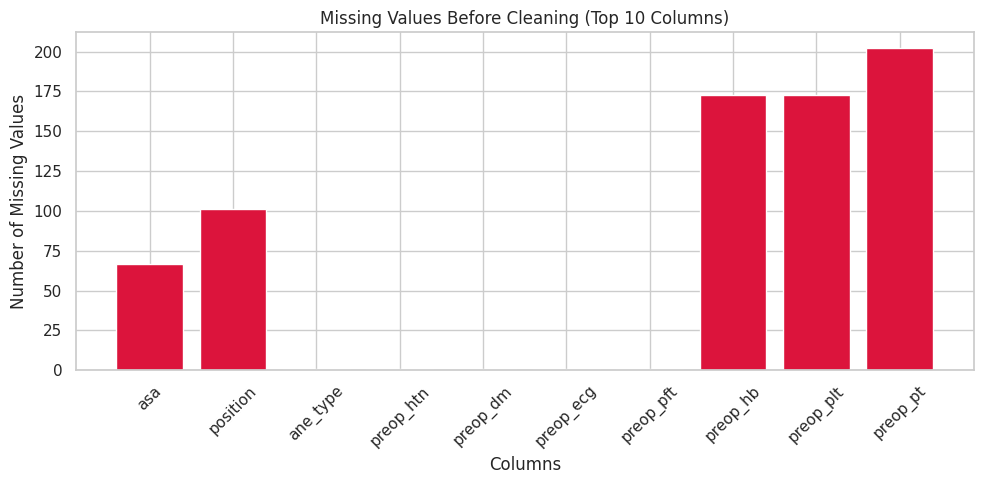

In [71]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

missing_before = data_for_raw.isnull().sum()
missing_before = missing_before[missing_before > 0]

plt.bar(
    missing_before.index[:10], missing_before.values[:10], color="crimson"
)
plt.title("Missing Values Before Cleaning (Top 10 Columns)")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

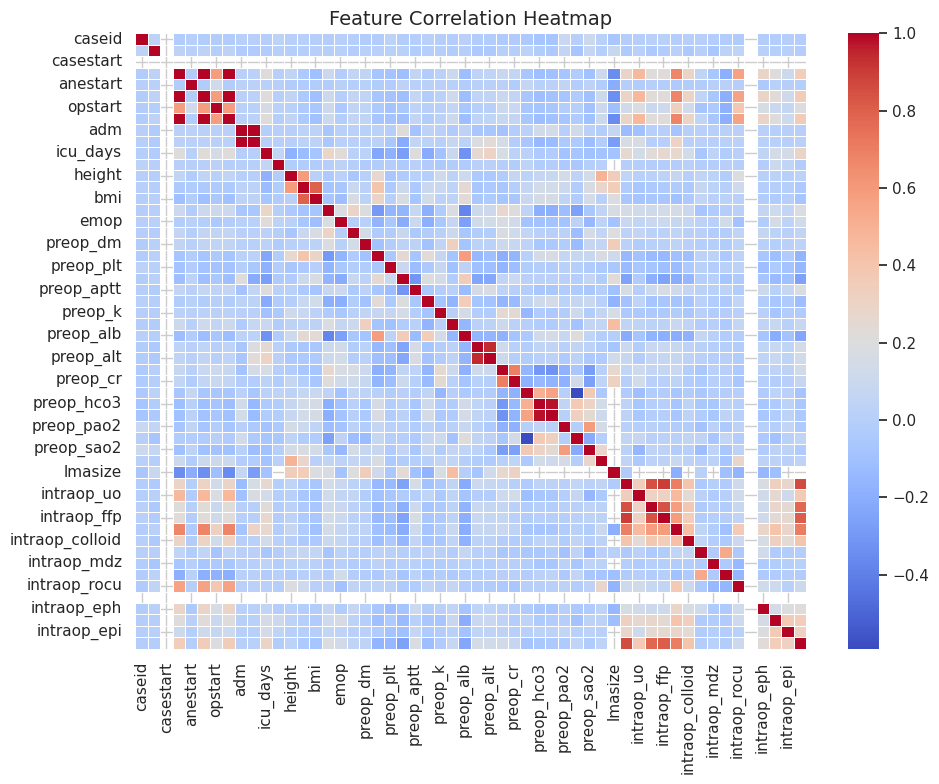

In [72]:
for col in data.columns:
    try:
        data[col] = pd.to_numeric(data[col])
    except:
        pass

numeric_data = data.select_dtypes(include=["number"])
if numeric_data.shape[1] > 1:
  plt.figure(figsize=(10, 8))
  correlation_matrix = numeric_data.corr()
  sns.heatmap(
      correlation_matrix,
      annot=False,
      fmt=".2f",
      cmap="coolwarm",
      linewidths=0.5,
      cbar=True,
  )
  plt.title("Feature Correlation Heatmap", fontsize=14)
  plt.tight_layout()
  plt.show()
else:
  print("Still no enough numeric columns to correlate. Check your dataset types!")

**Convert **

In [73]:
object_cols=data.select_dtypes(include=['object','string']).columns

for col in object_cols:
    non_null_data=data[col].dropna()
    if len(non_null_data)==0:
        continue

    date_series=pd.to_datetime(data[col],format='mixed',errors='coerce')
    if (date_series.notnull().sum()/len(non_null_data))>0.6:
        data[col]=date_series
        continue

    data_temp=data[col].astype(str).str.extract(r'(-?\d+\.?\d*)')[0]
    num_series=pd.to_numeric(data[col],errors='coerce')
    if (num_series.notnull().sum()/len(non_null_data))>0.6:
        data[col]=num_series
        continue

    unique_count=data[col].nunique()
    if (unique_count > 0) and (unique_count/len(data))<0.05:
        data[col]=data[col].astype('category')

    else:
        data[col]=data[col].astype(str)

In [74]:
data.dtypes[data.dtypes=='object']

dx        object
opname    object
dtype: object

In [75]:
data['dx']=data['dx'].astype('string')
data['opname']=data['opname'].astype('string')

In [76]:
data.dtypes[data.dtypes=='object']

Series([], dtype: object)

**Clean the worng text**

In [77]:
text_cols=data.select_dtypes(include=['string','category']).columns

for col in text_cols:
    data[col]=data[col].astype(str).str.lower().str.strip()
    value_counts = data[col].dropna().value_counts()
    unique_words = value_counts.index.tolist()
    if len(unique_words)==0:
        continue

    corrections={}
    for word in unique_words:
        matches = process.extract(str(word), unique_words,scorer=fuzz.ratio,score_cutoff=85)
        if matches:
            correct_word=max(matches,key=lambda x:value_counts[x[0]])[0]
            corrections[word]=correct_word

    if data[col].dtype.name=='category':
        data[col]=data[col].astype(str).replace(corrections).astype('category')

    else:
        data[col]=data[col].replace(corrections)

In [78]:
date_cols=data.select_dtypes(include=['datetime64','datetime']).columns

data[date_cols].isna().sum()

Series([], dtype: float64)

In [79]:
data=data.drop(columns=['caseid', 'subjectid'])

In [80]:
num_cols=data.select_dtypes(include=['int64','int32','float32','float64']).columns

for col in num_cols:
  q1 = data[col].quantile(0.25)
  q3 = data[col].quantile(0.75)
  iqr = q3 - q1
  upper_bound = q3 + (iqr * 1.5)
  lower_bound = q1 - (iqr * 1.5)
  data[col] = np.clip(data[col], lower_bound, upper_bound)

imputer = KNNImputer(n_neighbors=5)
data[num_cols] = imputer.fit_transform(data[num_cols])


**_____________________________________________________________________________________________________________________________________________________________________________________________**

In [81]:
print(f"Data Shape : {data.shape}")

missing_vals=data.isnull().sum()
total_missing=missing_vals.sum()
print(f"Total Missing Values : {total_missing}")

if total_missing > 0:
  print("Columns with missing values:")
  print(missing_vals[missing_vals > 0])
else:
  print("Dataset is clean from missing values")

print("\nData Types:")
print(data.dtypes.value_counts())

targets = ["intraop_ebl", "death_inhosp"]
print("\nTargets Check:")
for t in targets:
  if t in data.columns:
    print(f"Target '{t}' Missing : {data[t].isnull().sum()}")
  else:
    print(f"Target '{t}' not found!")

Data Shape : (3233, 72)
Total Missing Values : 0
Dataset is clean from missing values

Data Types:
float64    53
object     19
Name: count, dtype: int64

Targets Check:
Target 'intraop_ebl' Missing : 0
Target 'death_inhosp' Missing : 0


In [82]:
for col in data.columns:
  if data[col].isnull().sum() > 0:
    if data[col].dtype.name in ["category", "object", "string"]:
      data[col]=data[col].fillna("Unknown")
    elif pd.api.types.is_numeric_dtype(data[col]):
      data[col]=data[col].fillna(data[col].median())
    elif pd.api.types.is_datetime64_any_dtype(data[col]):
      data[col]=data[col].bfill().ffill()

total_missing = data.isnull().sum().sum()
print(f"count of missing : {total_missing}")

if total_missing == 0:
  print("Data is Cleaned")

count of missing : 0
Data is Cleaned


In [83]:
object_cols = data.select_dtypes(include=["object"]).columns
print(f"Number of categorical columns to encode: {len(object_cols)}")

Number of categorical columns to encode: 19


In [84]:
data=pd.get_dummies(data,columns=object_cols,drop_first=True)

In [85]:
data.columns = data.columns.str.strip()
object_cols = data.select_dtypes(include=["object", "category"]).columns.tolist()
print("Object columns found:", object_cols)
data = pd.get_dummies(data, columns=object_cols, drop_first=True)
print("New data shape after encoding:", data.shape)

Object columns found: []
New data shape after encoding: (3233, 848)


In [86]:
bool_cols=data.select_dtypes(include=["bool"]).columns
data[bool_cols]=data[bool_cols].astype(int)

In [87]:
print(f"Data Shape : {data.shape}")

missing_vals=data.isnull().sum()
total_missing=missing_vals.sum()
print(f"Total Missing Values : {total_missing}")

if total_missing > 0:
  print("Columns with missing values:")
  print(missing_vals[missing_vals > 0])
else:
  print("Dataset is clean from missing values.")

print("\nData Types:")
print(data.dtypes.value_counts())

targets = ["intraop_ebl","death_inhosp"]
print("\nTargets Check:")
for t in targets:
  if t in data.columns:
    print(f"target '{t}' Missing: {data[t].isnull().sum()}")
  else:
    print(f"target '{t}' not found!")

Data Shape : (3233, 848)
Total Missing Values : 0
Dataset is clean from missing values.

Data Types:
int64      795
float64     53
Name: count, dtype: int64

Targets Check:
target 'intraop_ebl' Missing: 0
target 'death_inhosp' Missing: 0


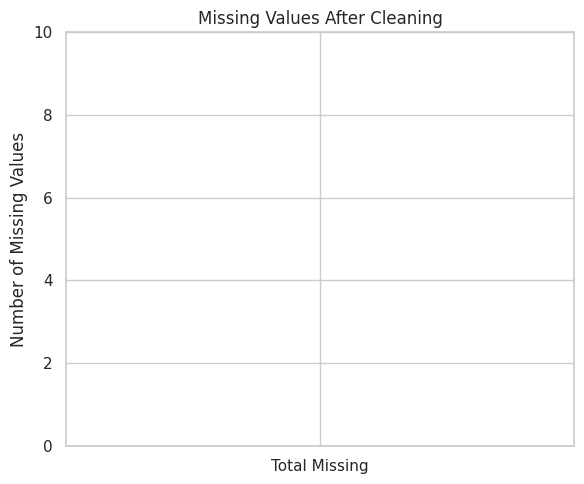

In [88]:
plt.figure(figsize=(6, 5))

total_after = data.isnull().sum().sum()

plt.bar(["Total Missing"], [total_after], color="seagreen", width=0.4)
plt.title("Missing Values After Cleaning")
plt.ylabel("Number of Missing Values")
plt.ylim(0, 10)

plt.tight_layout()
plt.show()

In [89]:
data.shape

(3233, 848)

In [92]:
X=data.drop(columns=['intraop_ebl','death_inhosp'])

y_reg = data["intraop_ebl"]
y_clf = data["death_inhosp"]

In [93]:
sscaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.9)
X_pca = pca.fit_transform(X_scaled)

X_pca.shape

(3233, 555)